# **# Classification de messages suspects — Analyse et modélisation**

L'objectif de ce projet est de développer un modèle capable de classifier des emails, puis de l'intégrer à une application Web.

Nous commencerons par étudier la qualité et la structure du dataset, avant de définir les prétraitements nécessaires et de comparer plusieurs approches de classification. Une attention particulière sera portée aux biais éventuels du corpus et à la capacité des modèles à généraliser à de nouveaux messages.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer
import re
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyClassifier
from lightgbm import LGBMClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, brier_score_loss, classification_report,
    confusion_matrix
)
from sklearn.base import clone
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import brier_score_loss, log_loss

pd.set_option("display.max_colwidth", 150)

# Login using e.g. `huggingface-cli login` to access this dataset

splits = {'train': 'data/train-00000-of-00001-4b508a55ac8e7a25.parquet', 'test': 'data/test-00000-of-00001-8a6d39996ec0fb5b.parquet'}
df = pd.read_parquet("hf://datasets/zionia/phishing-emails/" + splits["train"])

In [ ]:
df.head()

,text_combined,label
0,basil chupin oztzqpzotpgcomau aaron kulkis wrote per jessen wrote dave plater wrote seems cpus outpacing heatsinks 60c unstable temperature think ...,0
1,advice mon 27 dec 2004 11 16 55 0600 good day viewing record unable p prove mor tga g e r e financ e r e 3 00 however give 4 0 deal satisfied need...,1
2,daily top 10 nedhalla1965cadecocc daily top 10 cnncom top videos stories aug 1 2008 358 pm edt top 10 videos 1 montauk monster httpwwwcnncomvideop...,1
3,gale barton dwuvtmuvtcz safe highly effective ed medications work fast available site products help men ed effectively order _order ed treatment p...,1
4,alon camille pttayloranitesystemscom dear f1b9baedfa54992f95c68cf479eeb4a2 summer exact time take break work think health personal life glad assis...,1


In [ ]:
# Longueur maximale d'une cellule pour chaque colonne

longueurs = df.astype(str).apply(lambda col: col.str.len())

print(longueurs.max().sort_values(ascending=False))

text_combined    4279526
label                  1
dtype: int64


L'inspection des longueurs révèle 41 messages dépassant 50 000 caractères, dont un de plus de 4,27 millions. Ces observations peuvent fausser les statistiques descriptives et augmenter considérablement les coûts de traitement.

Nous les conservons pour l'instant afin d'examiner leur contenu avant toute décision de nettoyage.

In [ ]:
# Longueur de chaque valeur du DataFrame

longueurs = df.astype(str).apply(lambda col: col.str.len())

# Localisation des cellules dépassant 50 000 caractères

problemes = (
    longueurs.stack()
    .loc[lambda x: x > 50000]
    .reset_index()
)

problemes.columns = ["Index", "Colonne", "Nombre de caractères"]

print("Nombre de cellules problématiques :", len(problemes))
display(problemes.head(20))

print("\nLongueur maximale :", longueurs.max().max())

Nombre de cellules problématiques : 41


,Index,Colonne,Nombre de caractères
0,3209,text_combined,63641
1,3782,text_combined,63728
2,4240,text_combined,4279526
3,5932,text_combined,61800
4,7510,text_combined,50341
5,8776,text_combined,50879
6,10241,text_combined,50003
7,11261,text_combined,85395
8,12900,text_combined,63402
9,13196,text_combined,67772



Longueur maximale : 4279526


In [ ]:
display(df.loc[[4240]])

,text_combined,label
4240,mail system internal data mailerdaemonmonkeyor...,1


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 65988 entries, 0 to 65987
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   text_combined  65988 non-null  object
 1   label          65988 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 1.0+ MB


In [ ]:
df.isna().sum()

,0
text_combined,0
label,0


In [ ]:
# Analyse de la qualité des textes

df["text_length"] = df["text_combined"].fillna("").str.len()

print("Dimensions :", df.shape)
print("\nRépartition des classes :")
print(df["label"].value_counts())

print("\nValeurs manquantes :")
print(df.isna().sum())

print("\nDoublons textuels :")
print(df["text_combined"].duplicated().sum())

print("\nDistribution des longueurs :")
display(
    df["text_length"].describe(
        percentiles=[0.50, 0.90, 0.95, 0.99, 0.999]
    )
)

print("\nTextes dépassant 50 000 caractères :")
print((df["text_length"] > 50000).sum())

Dimensions : (65988, 3)

Répartition des classes :
label
1    34296
0    31692
Name: count, dtype: int64

Valeurs manquantes :
text_combined    0
label            0
text_length      0
dtype: int64

Doublons textuels :
269

Distribution des longueurs :


,text_length
count,6.598800e+04
mean,1.296807e+03
std,1.725281e+04
min,3.000000e+00
50%,5.580000e+02
90%,2.763000e+03
95%,3.643300e+03
99%,8.929650e+03
99.9%,3.775549e+04
max,4.279526e+06



Textes dépassant 50 000 caractères :
41


Le dataset contient 65 988 messages, avec une répartition relativement équilibrée entre les classes 0 et 1.

Aucune valeur manquante n'est détectée, mais nous identifions 269 doublons textuels, 32 messages de moins de 20 caractères et 41 messages particulièrement longs.

Ces observations nécessitent une inspection complémentaire pour distinguer les anomalies techniques des messages atypiques mais potentiellement exploitables.

In [ ]:
# Vérification des doublons et des labels contradictoires

doublons_contradictoires = (
    df.groupby("text_combined")["label"]
    .nunique()
    .gt(1)
    .sum()
)

print("Doublons textuels :", df["text_combined"].duplicated().sum())
print("Textes avec labels contradictoires :", doublons_contradictoires)

# Analyse des textes très courts

print("\nTextes de moins de 20 caractères :")
print((df["text_length"] < 20).sum())

# Répartition des très longs textes par classe

print("\nTextes > 50 000 caractères par classe :")
print(
    df.loc[df["text_length"] > 50000, "label"]
    .value_counts()
)

Doublons textuels : 269
Textes avec labels contradictoires : 0

Textes de moins de 20 caractères :
32

Textes > 50 000 caractères par classe :
label
0    31
1    10
Name: count, dtype: int64


In [ ]:
# Inspection des textes de moins de 20 caractères

textes_courts = df.loc[
    df["text_length"] < 20,
    ["text_combined", "label", "text_length"]
]

display(textes_courts.head(20))

,text_combined,label,text_length
2547,spam iyh b r x ac,1,17
3392,hej well pob hwyl,1,17
3953,geir goals,0,11
5429,rankings thank,0,14
10768,name wrong file bad,1,19
14482,clement hassan,1,14
15295,loading messages,1,17
16691,hi hasta entonces,1,18
20659,hi,1,3
20727,jif,1,4


In [ ]:
# Inspection des 10 observations les plus longues

textes_longs = df.nlargest(10, "text_length").copy()

# Affichage limité pour éviter de surcharger Colab

textes_longs["apercu"] = (
    textes_longs["text_combined"].str.slice(0, 500)
)

display(
    textes_longs[["label", "text_length", "apercu"]]
)

,label,text_length,apercu
4240,1,4279526,mail system internal data mailerdaemonmonkeyorg text part internal format mail folder real message created automatically mail system software dele...
63049,1,868304,email administrator security_updatewebmailcom security alert dear 0537324880001tonlinede 05af04navygovau 06af06navygovau 072477202tonlinede 085304...
40374,1,225918,adverting department advertsprj40cscom multipart message mime format _nextpart_000_01bc2b7489d1ccc0 contenttype multipartalternative boundary_next...
14205,1,178647,freeidddogmaslashnullorg multipart message mime format _nextpart_7hzmysbwvsemnjin8kg9y contenttype multipartalternative boundary_nextpart_7hzmysbw...
13265,0,160318,enron mentions enron wake call wall street journal 12 04 01 fall power giant dynegy hits back enron lawsuit claim failed merger entitles concern g...
39571,0,135072,blogs webmasterblogs change settings httpblogssettingsphp list updated weblogs oct 04 2002 303am lovealwaysnet httplovealwaysnet michaels cyber jo...
28357,0,126865,enron mentions 11 09 01 11 10 01 rival buy enron top energy trader financial fall new york times 11 10 01 regulators struggle marketplace created ...
49599,1,121161,gb2312btdrkrtk7vey159ft1bnx6c6vue webmasterszdrxcom gb2312bynw12squ0ru97nbqufq5rzktefx08nosbihorxn19puqsb3vp6horhtwbm gb2312bdew1bnawlvhu7btrbgowu...
41983,0,102779,whatiscom ndetplliststechtargetcom whatiscom february 12 2008 published whatiscom issue buzz alert people talking working case missed know youre b...
61831,0,98204,enron mentions 11 24 01 11 25 01 accounting peer review gets scrutiny new york times 11 25 01 alternate reality new york times 11 25 01 new york t...


In [ ]:
# Chargement de l'ensemble de test original

test_df = pd.read_parquet(
    "hf://datasets/zionia/phishing-emails/" + splits["test"]
)

# Recherche des textes présents dans les deux ensembles

doublons_train_test = test_df["text_combined"].isin(
    df["text_combined"]
).sum()

print("Dimensions du test :", test_df.shape)
print("Textes communs entre train et test :", doublons_train_test)

Dimensions du test : (16498, 2)
Textes communs entre train et test : 120


Nous avons identifié 120 textes du jeu de test également présents dans l'ensemble d'entraînement, soit environ 0,7 % du test.

Aucune contradiction d'étiquette n'a été détectée. Cependant, ces répétitions peuvent biaiser l'évaluation en présentant au modèle des messages déjà vus pendant l'apprentissage.

Nous conserverons les données originales et prévoirons une évaluation complémentaire sur un ensemble de test excluant ces chevauchements.

In [ ]:
# Recherche des textes communs aux deux ensembles

train_unique = df[
    ["text_combined", "label"]
].drop_duplicates()

test_overlap = test_df[
    test_df["text_combined"].isin(train_unique["text_combined"])
].copy()

# Comparaison des labels pour les mêmes textes

comparaison = test_overlap.merge(
    train_unique,
    on="text_combined",
    suffixes=("_test", "_train"),
    how="left"
)

print("Lignes de test présentes dans le train :", len(test_overlap))

print(
    "Textes communs distincts :",
    test_overlap["text_combined"].nunique()
)

print(
    "Conflits de labels entre train et test :",
    (comparaison["label_test"] != comparaison["label_train"]).sum()
)

print("\nRépartition des chevauchements par classe :")
print(test_overlap["label"].value_counts())

# Quelques exemples sans afficher les textes entiers

comparaison["apercu"] = comparaison["text_combined"].str[:150]

display(
    comparaison[
        ["apercu", "label_train", "label_test"]
    ].head(10)
)

Lignes de test présentes dans le train : 120
Textes communs distincts : 120
Conflits de labels entre train et test : 0

Répartition des chevauchements par classe :
label
0    107
1     13
Name: count, dtype: int64


,apercu,label_train,label_test
0,2 survey information email 5 7 01 current notes user ensure experience successful migration notes outlook necessary gather individual user informa...,0,0
1,latest frontera doc forwarded bob hall na enron 03 09 2001 12 05 pm leslie reeves ect 03 07 2001 03 35 pm bob hall na enron enron cc subject lates...,0,0
2,summary spreadsheet data vendor research model development hi fyi updated spreadsheet summarizing data vendor research model development please le...,0,0
3,visit may 4 th vince per susan email want go luncheon john hennessey say lunch going get invite thing day 9 00 larry thorne energy derivatives cla...,0,0
4,new building egm headcount report please let know questions thanks laurel,0,0
5,mgmt 656 enclosed please find final grade rosters mgmt 656 grades due office later friday may 4 remember university deadline graduating students t...,0,0
6,noms actual flow 03 20 01 agree nominations eileen ponton 03 21 2001 11 08 26 david avila lsp enserch us tu charlie stone texas utilities tu melis...,0,0
7,confirmations talked steve jackson aep looks like may want use decaf intramonth confirmations come way confirm certain deals deals add meeting nex...,0,0
8,visiting enron may 4 th susan thanks makes sense call christie explain objectives visit may vince susan c hansen 04 06 2001 06 14 10 pm vince j ka...,0,0
9,confidence back hello boyfriend began problems erections older suggested look vlagrra softtabs boy glad first time tried one 50 mg piil nothing to...,1,1


In [ ]:
# Comparaison des longueurs selon la classe sur les deux ensembles fournis

for name, data in [("Train", df), ("Test", test_df)]:

    temp = data.copy()
    temp["text_length"] = temp["text_combined"].str.len()

    print(f"\n--- {name} ---")

    display(
        temp.groupby("label")["text_length"]
        .agg(["count", "mean", "median", "std", "max"])
        .round(2)
    )

    print(
        "Doublons internes :",
        temp["text_combined"].duplicated().sum()
    )


--- Train ---


,count,mean,median,std,max
label,,,,,
0,31692,1525.50,782.0,3560.28,160318
1,34296,1085.48,389.0,23683.76,4279526


Doublons internes : 269

--- Test ---


,count,mean,median,std,max
label,,,,,
0,7903,1578.61,769.0,4195.93,129025
1,8595,960.38,396.0,1750.22,83737


Doublons internes : 19


Les messages de classe 0 sont généralement plus longs : leur médiane est de 782 caractères dans le train, contre 389 pour la classe 1. Cette tendance se retrouve dans le test (769 contre 396 caractères), ce qui suggère une certaine stabilité des distributions centrales.

La longueur pourrait constituer un indice de classification, mais aussi refléter des différences de provenance entre les messages. Nous éviterons donc de l'interpréter comme un indicateur de fraude à elle seule.

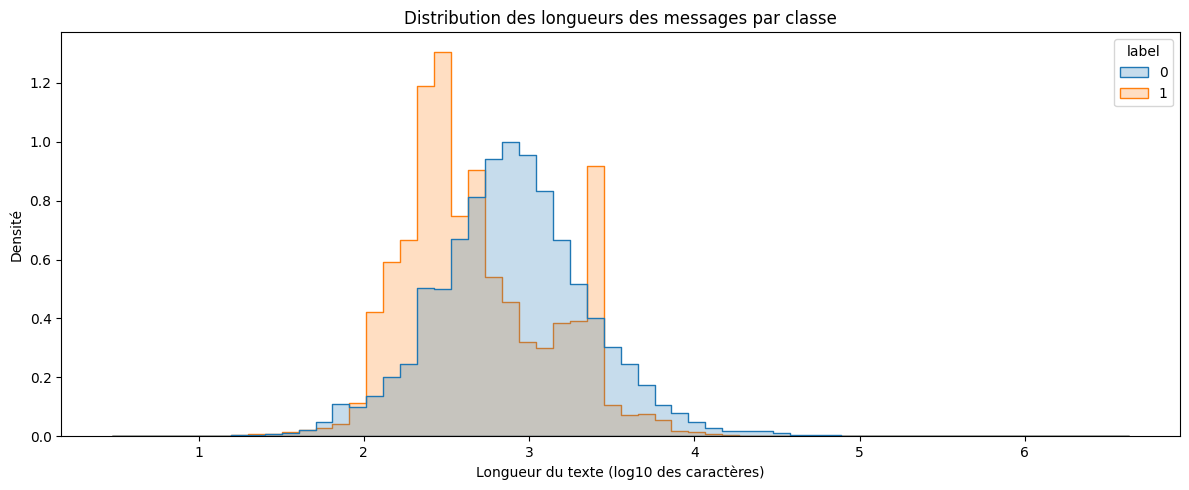

In [ ]:
df["text_length"] = df["text_combined"].str.len()

# Copie légère destinée uniquement à la visualisation

df_plot = df[["label", "text_length"]].copy()

# Transformation logarithmique pour visualiser
# les textes courts et longs sur une même échelle car la classe 0 est très asymétrique

df_plot["log_length"] = np.log10(df_plot["text_length"])

plt.figure(figsize=(12, 5))

sns.histplot(
    data=df_plot,
    x="log_length",
    hue="label",
    bins=60,
    stat="density",
    common_norm=False,
    element="step"
)

plt.title("Distribution des longueurs des messages par classe")
plt.xlabel("Longueur du texte (log10 des caractères)")
plt.ylabel("Densité")

plt.tight_layout()
plt.show()

La transformation logarithmique permet de réduire l'influence visuelle des valeurs extrêmes.

La classe 0 présente une distribution approximativement en cloche après transformation, tandis que celle de la classe 1 semble comporter plusieurs pics.

Cette différence pourrait révéler une hétérogénéité plus importante des longueurs dans la classe 1.

Les distributions se chevauchent néanmoins, ce qui indique que la longueur des messages ne suffit pas, à elle seule, à distinguer les deux classes.

In [ ]:
# Comparaison de l'asymétrie des distributions

for label in [0, 1]:
    longueurs = df.loc[df["label"] == label, "text_length"]

    print(f"\nClasse {label}")
    print(f"Asymétrie originale : {longueurs.skew():.3f}")
    print(f"Asymétrie logarithmique : {np.log10(longueurs).skew():.3f}")


Classe 0
Asymétrie originale : 14.813
Asymétrie logarithmique : 0.168

Classe 1
Asymétrie originale : 173.385
Asymétrie logarithmique : 0.527


La transformation logarithmique réduit fortement l'asymétrie des distributions : le coefficient passe de 14,813 à 0,168 pour la classe 0, et de 173,385 à 0,527 pour la classe 1.

La classe 0 devient presque symétrique, tandis que la classe 1 conserve une asymétrie positive et présente plusieurs pics visibles. Ces derniers pourraient traduire une certaine hétérogénéité des messages, ce que nous allons approfondir.

Cette transformation facilite la visualisation des longueurs sans supprimer les observations extrêmes. Elle ne permet toutefois pas d'affirmer que les distributions suivent une loi normale.

In [ ]:
# Limitation de la longueur des textes pour l'EDA uniquement

textes_eda = df["text_combined"].astype(str).str[:12000]

# Vectorisation du vocabulaire

vectorizer = CountVectorizer(
    stop_words="english",
    binary=True,
    min_df=20,
    max_df=0.95,
    max_features=8000
)

X_counts = vectorizer.fit_transform(textes_eda)

print("Dimensions :", X_counts.shape)
print("Nombre de termes :", len(vectorizer.get_feature_names_out()))

Dimensions : (65988, 8000)
Nombre de termes : 8000


Nous utilisons CountVectorizer pour étudier le vocabulaire des deux classes. La représentation binaire permet de mesurer la proportion de messages contenant chaque terme, indépendamment de son nombre de répétitions.

Les mots-outils anglais et les termes extrêmement rares sont exclus afin de faciliter l'interprétation. La taille du vocabulaire est limitée à 8 000 termes pour cette analyse exploratoire.

In [ ]:
# Identification des observations de chaque classe

mask_0 = df["label"].to_numpy() == 0
mask_1 = df["label"].to_numpy() == 1

# Fréquence documentaire relative dans chaque classe

freq_0 = np.asarray(X_counts[mask_0].mean(axis=0)).ravel()
freq_1 = np.asarray(X_counts[mask_1].mean(axis=0)).ravel()

# Construction du tableau comparatif

vocab = pd.DataFrame({
    "terme": vectorizer.get_feature_names_out(),
    "classe_0_pct": freq_0 * 100,
    "classe_1_pct": freq_1 * 100
})

# Différence de fréquence entre les deux classes

vocab["ecart"] = vocab["classe_1_pct"] - vocab["classe_0_pct"]

print("Termes davantage présents en classe 1 :")
display(vocab.nlargest(15, "ecart").round(2))

print("Termes davantage présents en classe 0 :")
display(vocab.nsmallest(15, "ecart").round(2))

Termes davantage présents en classe 1 :


,terme,classe_0_pct,classe_1_pct,ecart
1618,company,6.42,20.01,13.59
5969,receive,5.57,18.77,13.20
4819,money,2.57,14.57,12.00
4331,life,2.69,13.36,10.67
1535,cnn,0.10,10.53,10.43
1245,cable,0.53,10.55,10.02
195,30303,0.03,10.04,10.01
1536,cnncom,0.03,10.04,10.01
829,atlanta,0.21,10.20,9.99
3217,georgia,0.38,10.26,9.88


Termes davantage présents en classe 0 :


,terme,classe_0_pct,classe_1_pct,ecart
7927,wrote,24.37,0.33,-24.04
4369,list,27.17,6.03,-21.14
6979,subject,23.79,4.52,-19.27
2622,enron,17.91,0.01,-17.91
7218,thanks,22.30,5.22,-17.08
1341,cc,15.15,0.29,-14.86
4337,like,24.64,10.41,-14.23
4520,mailing,17.08,3.01,-14.07
4184,know,22.58,8.87,-13.71
353,_______________________________________________,13.18,0.41,-12.77


L'analyse du vocabulaire montre plusieurs différences entre les classes. Les termes money, receive et click sont davantage présents dans la classe 1, tandis que wrote, subject et enron caractérisent davantage la classe 0. Cependant, certains termes semblent davantage liés à la provenance des messages qu'à leur contenu, notamment cnn, cnncom et enron.

Ces résultats suggèrent un possible biais de source : un modèle pourrait apprendre à reconnaître certains corpus plutôt que les caractéristiques réelles des messages frauduleux.

Une inspection complémentaire est donc nécessaire avant de décider des traitements à appliquer.

In [ ]:
# Identification des messages contenant les termes suspects

termes = ["cnn", "cnncom", "30303", "atlanta", "georgia"]

presences = {}

for terme in termes:
    idx = vectorizer.vocabulary_[terme]
    presences[terme] = X_counts[:, idx].toarray().ravel().astype(bool)

# Vérification de la présence simultanée des termes

mask_commun = (
    presences["cnncom"]
    & presences["30303"]
    & presences["atlanta"]
)

print("Messages contenant les trois termes :", mask_commun.sum())

print("\nRépartition par classe :")
print(df.loc[mask_commun, "label"].value_counts())

# Inspection de quelques exemples

exemples = df.loc[mask_commun, ["text_combined", "label"]].head(5).copy()

exemples["apercu"] = exemples["text_combined"].str[:400]

display(exemples[["label", "apercu"]])

Messages contenant les trois termes : 3453

Répartition par classe :
label
1    3444
0       9
Name: count, dtype: int64


,label,apercu
2,1,daily top 10 nedhalla1965cadecocc daily top 10 cnncom top videos stories aug 1 2008 358 pm edt top 10 videos 1 montauk monster httpwwwcnncomvideop...
7,1,cnn alerts yamahadaremconsultingcomau cnn alerts custom alert alert name custom alert north koreas nuke aimed washington discovered fri 8 aug 2008...
25,1,cnn alerts jacobushcuuykayapologiseto cnn alerts custom alert alert name custom alert best way file tax returns government gives money fri 8 aug 2...
47,1,daily top 10 yamna1995click2learncom daily top 10 cnncom top videos stories aug 1 2008 358 pm edt top 10 videos 1 paris hilton takes mccain httpww...
52,1,daily top 10 bianchi1986freemailselfiporg daily top 10 cnncom top videos stories aug 1 2008 358 pm edt top 10 videos 1 paris hilton takes mccain h...


In [ ]:
# Analyse des messages contenant la signature CNN

cnn_df = df.loc[mask_commun, ["text_combined", "label"]].copy()

# Vérification des doublons exacts

print("Nombre de messages :", len(cnn_df))
print("Messages uniques :", cnn_df["text_combined"].nunique())
print("Doublons exacts :", cnn_df["text_combined"].duplicated().sum())

# Recherche de formats récurrents

motifs = ["cnn alerts", "daily top 10", "cnncom"]

for motif in motifs:
    nb = cnn_df["text_combined"].str.contains(
        motif, case=False, regex=False
    ).sum()

    print(f"{motif} : {nb} messages")

Nombre de messages : 3453
Messages uniques : 3453
Doublons exacts : 0
cnn alerts : 1128 messages
daily top 10 : 2324 messages
cnncom : 3453 messages


L'investigation de la signature CNN révèle 3 453 messages distincts, dont 3 444 appartiennent à la classe 1. Aucun doublon exact n'est présent, mais les expressions "cnn alerts" et "daily top 10" reviennent fréquemment.

Ces observations suggèrent que des messages différents peuvent partager des structures très similaires, introduisant un possible biais de provenance.

Nous ne supprimons pas ces termes à ce stade : leur rôle devra être évalué lors de la modélisation, notamment en comparant les performances sur des messages issus de sources différentes.

In [ ]:
# Identification des messages contenant le terme "enron"

idx_enron = vectorizer.vocabulary_["enron"]

mask_enron = X_counts[:, idx_enron].toarray().ravel().astype(bool)

enron_df = df.loc[mask_enron, ["text_combined", "label"]].copy()

print("Messages contenant 'enron' :", len(enron_df))
print("Messages uniques :", enron_df["text_combined"].nunique())
print("Doublons exacts :", enron_df["text_combined"].duplicated().sum())

print("\nRépartition par classe :")
print(enron_df["label"].value_counts())

# Inspection de quelques messages

exemples = enron_df.sample(
    n=min(5, len(enron_df)),
    random_state=42
).copy()

exemples["apercu"] = exemples["text_combined"].str[:350]

display(exemples[["label", "apercu"]])

Messages contenant 'enron' : 5679
Messages uniques : 5535
Doublons exacts : 144

Répartition par classe :
label
0    5677
1       2
Name: count, dtype: int64


,label,apercu
13034,0,agreed haedicke given travis mary cook legal understand digging contracts want verify litigation scope lawsuits el paso swaps would preclude incl...
10642,0,year end 2000 performance feedback note receive message time selected reviewer selected participate year end 2000 performance management process p...
20705,0,fw capacity south ignacio per perry message 33 000 subscribe south la plata blanco receipt point available capacity go transmission capacity wfs l...
44294,0,confidential prc results hi got message 4 pm original message kitchen louise sent friday july 20 2001 1 07 pm melodick kim subject fw confidential...
57720,0,eog pronghorn location gas control make assumption gas flow efm installed need info balance system ds bob burleson 11 08 2000 07 29 earl chanley e...


L'investigation révèle que 5 677 des 5 679 messages contenant enron appartiennent à la classe 0 (99,96 %). Ces messages présentent également une forte présence de métadonnées telles que subject et cc.

Ce phénomène rappelle celui observé avec les signatures CNN, fortement associées à la classe 1. Les deux groupes suggèrent que certaines caractéristiques du corpus pourraient être corrélées aux labels indépendamment du caractère frauduleux des messages.

Une excellente accuracy sur un dataset ne garantit pas une bonne généralisation : un modèle peut apprendre des particularités du corpus plutôt que les caractéristiques du phishing.

Cette hypothèse sera testée lors de la modélisation, en comparant notamment les performances sur des messages avec et sans ces signatures.

In [ ]:
# Termes structurels caractéristiques des emails
termes_structure = ["wrote", "subject", "cc", "thanks", "mailing"]

resultats = []

for terme in termes_structure:
    idx = vectorizer.vocabulary_[terme]

    presence = X_counts[:, idx].toarray().ravel().astype(bool)

    taux_enron = presence[mask_enron].mean() * 100
    taux_autres = presence[~mask_enron].mean() * 100

    resultats.append({
        "terme": terme,
        "enron_pct": taux_enron,
        "autres_pct": taux_autres,
        "ecart": taux_enron - taux_autres
    })

comparaison_enron = pd.DataFrame(resultats)

display(
    comparaison_enron.sort_values("ecart", ascending=False).round(2)
)

,terme,enron_pct,autres_pct,ecart
1,subject,63.20,9.12,54.08
2,cc,56.75,2.78,53.97
3,thanks,39.00,11.01,27.99
0,wrote,2.94,12.71,-9.77
4,mailing,0.83,10.61,-9.78


In [ ]:
# Deux signatures, sans ambiguïté si elles se chevauchent

cnn_seul = mask_commun & ~mask_enron
enron_seul = mask_enron & ~mask_commun

couverture = cnn_seul | enron_seul

# Règle : CNN -> 1, Enron -> 0

predictions = np.full(len(df), -1)

predictions[cnn_seul] = 1
predictions[enron_seul] = 0

y_true = df["label"].to_numpy()

print("Messages couverts :", couverture.sum())
print(f"Couverture du train : {couverture.mean():.2%}")

print(
    "Exactitude sur les messages couverts :",
    f"{(predictions[couverture] == y_true[couverture]).mean():.2%}"
)

print(
    "Erreurs sur les messages couverts :",
    (predictions[couverture] != y_true[couverture]).sum()
)

print("Messages sans prédiction :", (~couverture).sum())

Messages couverts : 9132
Couverture du train : 13.84%
Exactitude sur les messages couverts : 99.88%
Erreurs sur les messages couverts : 11
Messages sans prédiction : 56856


Une règle manuelle fondée sur les signatures CNN et Enron atteint 99,88 % d'exactitude sur 9 132 messages, soit seulement 13,84 % du train.

Cette performance élevée s'explique par la forte corrélation entre ces signatures et les labels. Elle ne constitue pas une mesure de généralisation, puisque les règles ont été définies après l'exploration des mêmes données et ne couvrent pas l'ensemble du corpus.

L'inspection des 11 erreurs montre également que ces signatures ne déterminent pas systématiquement la classe réelle d'un message.

Une excellente accuracy sur un dataset ne garantit donc pas une bonne généralisation : un modèle peut exploiter des particularités des données plutôt que les caractéristiques du phishing.

Cette observation justifie une évaluation des futurs modèles sur différents sous-groupes et, idéalement, sur des données de provenance indépendante.

In [ ]:
# Identification des erreurs de la règle

mask_erreurs = couverture & (predictions != y_true)

erreurs = df.loc[
    mask_erreurs, ["text_combined", "label"]
].copy()

erreurs["signature"] = np.where(
    cnn_seul[mask_erreurs],
    "CNN",
    "Enron"
)

erreurs["prediction_regle"] = predictions[mask_erreurs]
erreurs["apercu"] = erreurs["text_combined"].str[:600]

display(
    erreurs[["signature", "label", "prediction_regle", "apercu"]]
)

,signature,label,prediction_regle,apercu
12180,Enron,1,0,ramsey mj_ramsey1gmailcn greetings good day may trouble sense personal achievement reward opportunity properly taken advantage mr michael jay rams...
14117,CNN,0,1,cnn alerts cnnalertsmailcnncom cnn alerts bush alert name bush reaction verdict gitmo terror trial 080608 0234 pm edt osama bin ladens former driv...
26176,CNN,0,1,cnn alerts cnnalertsmailcnncom cnn alerts bush alert name bush iraqs oilfueled surplus could hit 80 billion report says 080508 0818 pm edt iraq ra...
31228,CNN,0,1,cnn alerts cnnalertsmailcnncom cnn alerts bush alert name bush mccain points independence obama likens bush 080508 0300 pm edt string ads attackin...
31681,CNN,0,1,cnn alerts cnnalertsmailcnncom cnn alerts bush alert name bush mccain plays risky game negative ads author says 080108 0327 pm edt john avlon self...
31868,CNN,0,1,cnn alerts cnnalertsmailcnncom cnn alerts bush alert name bush selfdeportation program kicks takers 080608 0147 edt wanted illegal immigrants clea...
34737,CNN,0,1,cnn alerts cnnalertsmailcnncom cnn alerts bush alert name bush house panel votes cite karl rove contempt 073008 0235 pm edt house panel wednesday ...
38187,CNN,0,1,cnn alerts cnnalertsmailcnncom cnn alerts bush alert name bush us poland strike missile deal russia objects 070208 1023 pm edt united states polan...
47631,Enron,1,0,best regards dear friend good day may trouble sense personal achievement reward opportunity properly taken advantage mr michael ramsey representat...
48100,CNN,0,1,cnn alerts cnnalertsmailcnncom cnn alerts bush alert name bush bush chide china human rights 080608 0115 pm edt president bush speech scheduled ev...


In [ ]:
# Limite temporaire pour l'EDA, distincte de celle utilisée pour les modèles

textes_eda = df["text_combined"].fillna("").astype(str).str[:12000]
vectorizer_eda = CountVectorizer(
    stop_words="english", binary=True, min_df=20,
    max_df=0.95, max_features=8000
)
X_counts_eda = vectorizer_eda.fit_transform(textes_eda)

mask_0 = df["label"].to_numpy() == 0
mask_1 = df["label"].to_numpy() == 1
freq_0 = np.asarray(X_counts_eda[mask_0].mean(axis=0)).ravel()
freq_1 = np.asarray(X_counts_eda[mask_1].mean(axis=0)).ravel()
vocab_eda = pd.DataFrame({
    "terme": vectorizer_eda.get_feature_names_out(),
    "classe_0_pct": freq_0 * 100,
    "classe_1_pct": freq_1 * 100,
})
vocab_eda["ecart_pts"] = vocab_eda["classe_1_pct"] - vocab_eda["classe_0_pct"]
print("Vocabulaire EDA :", X_counts_eda.shape)
display(vocab_eda.nlargest(15, "ecart_pts").round(2))
display(vocab_eda.nsmallest(15, "ecart_pts").round(2))

Vocabulaire EDA : (65988, 8000)


,terme,classe_0_pct,classe_1_pct,ecart_pts
1618,company,6.42,20.01,13.59
5969,receive,5.57,18.77,13.20
4819,money,2.57,14.57,12.00
4331,life,2.69,13.36,10.67
1535,cnn,0.10,10.53,10.43
1245,cable,0.53,10.55,10.02
195,30303,0.03,10.04,10.01
1536,cnncom,0.03,10.04,10.01
829,atlanta,0.21,10.20,9.99
3217,georgia,0.38,10.26,9.88


,terme,classe_0_pct,classe_1_pct,ecart_pts
7927,wrote,24.37,0.33,-24.04
4369,list,27.17,6.03,-21.14
6979,subject,23.79,4.52,-19.27
2622,enron,17.91,0.01,-17.91
7218,thanks,22.30,5.22,-17.08
1341,cc,15.15,0.29,-14.86
4337,like,24.64,10.41,-14.23
4520,mailing,17.08,3.01,-14.07
4184,know,22.58,8.87,-13.71
353,_______________________________________________,13.18,0.41,-12.77


In [ ]:
# Mesure exploratoire des deux signatures sur le train, sans modélisation

vocab_eda_index = vectorizer_eda.vocabulary_
def contient_mot(mot):
    return X_counts_eda[:, vocab_eda_index[mot]].toarray().ravel().astype(bool)

signature_cnn = contient_mot("cnncom") & contient_mot("30303") & contient_mot("atlanta")
signature_enron = contient_mot("enron")
cnn_seul = signature_cnn & ~signature_enron
enron_seul = signature_enron & ~signature_cnn
couverture = cnn_seul | enron_seul
pred_regle = np.full(len(df), -1)
pred_regle[cnn_seul] = 1
pred_regle[enron_seul] = 0
labels_train_orig = df["label"].to_numpy()

print("Couverture :", couverture.sum(), f"({couverture.mean():.2%})")
print("Accuracy SUR LES MESSAGES COUVERTS :",
      f"{(pred_regle[couverture] == labels_train_orig[couverture]).mean():.2%}")
print("Erreurs :", (pred_regle[couverture] != labels_train_orig[couverture]).sum())

Couverture : 9132 (13.84%)
Accuracy SUR LES MESSAGES COUVERTS : 99.88%
Erreurs : 11


L'EDA a révélé des doublons, des valeurs extrêmes et des signatures de provenance fortement associées aux labels. Nous choisissons de conserver les messages courts ainsi que les termes CNN/Enron, afin de ne pas éliminer arbitrairement des informations potentiellement utiles.

Pour maîtriser le coût de calcul, les textes sont limités à 20 000 caractères. Nous normalisons ensuite la casse et les espaces, puis éliminons les textes devenus identiques après préparation. Cette limite est un compromis expérimental : elle peut entraîner une perte d'information dans les messages les plus longs.

Le dataset est ensuite séparé en apprentissage (80 %) et validation (20 %), avec stratification des classes. Le test fourni reste réservé à l'évaluation finale.

In [ ]:
MAX_CHARS = 20_000
RANDOM_STATE = 42

def preparer_textes(serie):

    # Même prétraitement à reproduire dans la WebApp

    return (serie.fillna("").astype(str)
            .str[:MAX_CHARS]
            .str.lower()
            .str.replace(r"\s+", " ", regex=True)
            .str.strip())

model_df = df[["text_combined", "label"]].copy()
model_df["model_text"] = preparer_textes(model_df["text_combined"])

n_avant = len(model_df)
model_df = model_df.loc[model_df["model_text"].ne("")].copy()

# Des textes devenus identiques après troncature pourraient avoir deux labels.

nb_labels = model_df.groupby("model_text")["label"].transform("nunique")
n_conflits = model_df.loc[nb_labels.gt(1), "model_text"].nunique()
model_df = model_df.loc[nb_labels.eq(1)].drop_duplicates("model_text").copy()

print("Observations initiales :", n_avant)
print("Textes ambigus après préparation (distincts) :", n_conflits)
print("Observations conservées :", len(model_df))
print("Répartition après nettoyage :")
print(model_df["label"].value_counts(normalize=True).round(3))

X_train, X_val, y_train, y_val = train_test_split(
    model_df["model_text"], model_df["label"],
    test_size=0.20, stratify=model_df["label"],
    random_state=RANDOM_STATE
)
assert set(X_train).isdisjoint(set(X_val))
print("Train :", len(X_train), "| Validation :", len(X_val))

Observations initiales : 65988
Textes ambigus après préparation (distincts) : 0
Observations conservées : 65718
Répartition après nettoyage :
label
1    0.521
0    0.479
Name: proportion, dtype: float64
Train : 52574 | Validation : 13144


Nous utilisons TF-IDF avec des unigrammes et bigrammes pour représenter le vocabulaire et les expressions des messages. La vectorisation est intégrée aux pipelines : son vocabulaire est ainsi appris uniquement sur le train, afin d'éviter une fuite de données vers la validation.

Deux approches complémentaires sont comparées :

- **LightGBM** : modèle de boosting basé sur des arbres, permettant d'explorer des interactions non linéaires.
- **MLP** : réseau neuronal multicouche, capable d'apprendre des combinaisons de caractéristiques TF-IDF.

Un DummyClassifier sert de référence minimale.

Nous comparerons les modèles à l'aide de l'accuracy, de la précision, du rappel, du F1-score et de métriques probabilistes.

In [ ]:
def pipeline_tfidf_compact(classifieur):
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=False,
            ngram_range=(1, 2),
            min_df=3,
            max_df=0.98,
            max_features=20_000,
            sublinear_tf=True,
            dtype=np.float32
        )),
        ("modele", classifieur)
    ])


modeles_ml = {
    "Dummy": DummyClassifier(strategy="most_frequent"),

    "LightGBM": pipeline_tfidf_compact(
        LGBMClassifier(
            n_estimators=250,
            learning_rate=0.05,
            num_leaves=31,
            min_child_samples=40,
            reg_lambda=1.0,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            verbosity=-1
        )
    ),

    "MLP": pipeline_tfidf_compact(
        MLPClassifier(
            hidden_layer_sizes=(64,),
            activation="relu",
            alpha=0.001,
            batch_size=256,
            max_iter=20,
            early_stopping=True,
            n_iter_no_change=4,
            random_state=RANDOM_STATE
        )
    )
}

def mesurer(y_vrai, probas, nom):
    preds = (np.asarray(probas) >= 0.5).astype(int)
    return {
        "modèle": nom,
        "accuracy": accuracy_score(y_vrai, preds),
        "precision_1": precision_score(y_vrai, preds, zero_division=0),
        "recall_1": recall_score(y_vrai, preds, zero_division=0),
        "f1_1": f1_score(y_vrai, preds, zero_division=0),
        "f1_macro": f1_score(y_vrai, preds, average="macro", zero_division=0),
        "roc_auc": roc_auc_score(y_vrai, probas),
        "brier": brier_score_loss(y_vrai, probas),
    }

resultats_ml = []

for nom, modele in modeles_ml.items():
    print("Entraînement :", nom)

    modele.fit(X_train, y_train)

    probas = modele.predict_proba(X_val)[:, 1]

    resultats_ml.append(
        mesurer(y_val, probas, nom)
    )

comparaison_ml = (
    pd.DataFrame(resultats_ml)
    .sort_values("f1_1", ascending=False)
)

display(comparaison_ml.round(4))

Entraînement : Dummy
Entraînement : LightGBM


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Entraînement : MLP


,modèle,accuracy,precision_1,recall_1,f1_1,f1_macro,roc_auc,brier
2,MLP,0.9901,0.9909,0.9901,0.9905,0.9901,0.9992,0.0082
1,LightGBM,0.9851,0.9806,0.9910,0.9858,0.9851,0.9989,0.0124
0,Dummy,0.5214,0.5214,1.0000,0.6854,0.3427,0.5000,0.4786


Les deux modèles présentent des performances très élevées en validation : 98,51 % d'accuracy pour LightGBM et 99,01 % pour le MLP.

Le DummyClassifier obtient seulement 52,14 % d'accuracy. Son F1-score de 68,54 % s'explique par sa prédiction systématique de la classe majoritaire et ne traduit pas une véritable capacité de discrimination.

Les performances de LightGBM et du MLP sont encourageantes, mais particulièrement élevées au regard des biais observés durant l'EDA. Nous devons donc vérifier si ces résultats reflètent une bonne généralisation ou si les modèles bénéficient de caractéristiques propres au dataset.

In [ ]:
# Comparaison des performances entre train et validation

resultats_generalisation = []

for nom in ["LightGBM", "MLP"]:
    modele = modeles_ml[nom]

    # Probabilités sur les deux ensembles

    proba_train = modele.predict_proba(X_train)[:, 1]
    proba_val = modele.predict_proba(X_val)[:, 1]

    # Métriques identiques pour une comparaison cohérente

    scores_train = mesurer(y_train, proba_train, nom)
    scores_val = mesurer(y_val, proba_val, nom)

    resultats_generalisation.append({
        "modèle": nom,
        "accuracy_train": scores_train["accuracy"],
        "accuracy_val": scores_val["accuracy"],
        "écart_accuracy": scores_train["accuracy"] - scores_val["accuracy"],
        "f1_train": scores_train["f1_1"],
        "f1_val": scores_val["f1_1"],
        "écart_f1": scores_train["f1_1"] - scores_val["f1_1"]
    })

generalisation_df = pd.DataFrame(resultats_generalisation)

display(generalisation_df.round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,modèle,accuracy_train,accuracy_val,écart_accuracy,f1_train,f1_val,écart_f1
0,LightGBM,0.9901,0.9851,0.0050,0.9906,0.9858,0.0048
1,MLP,0.9965,0.9901,0.0064,0.9966,0.9905,0.0061


In [ ]:
# Identification des signatures dans la validation

textes_val = X_val.astype(str)

mask_cnn_val = (
    textes_val.str.contains(r"\bcnncom\b", regex=True)
    & textes_val.str.contains(r"\b30303\b", regex=True)
    & textes_val.str.contains(r"\batlanta\b", regex=True)
)

mask_enron_val = textes_val.str.contains(
    r"\benron\b", regex=True
)

# Attribution d'un groupe à chaque message

groupes_val = np.select(
    [
        mask_cnn_val & ~mask_enron_val,
        mask_enron_val & ~mask_cnn_val,
        mask_cnn_val & mask_enron_val
    ],
    ["CNN", "Enron", "CNN + Enron"],
    default="Sans signatures"
)

resultats_groupes = []

for nom in ["LightGBM", "MLP"]:
    modele = modeles_ml[nom]

    probas = modele.predict_proba(X_val)[:, 1]
    preds = (probas >= 0.5).astype(int)
    y_reel = y_val.to_numpy()

    for groupe in np.unique(groupes_val):
        mask = groupes_val == groupe

        resultats_groupes.append({
            "modèle": nom,
            "groupe": groupe,
            "messages": mask.sum(),
            "classe_1_pct": 100 * y_reel[mask].mean(),
            "accuracy": accuracy_score(
                y_reel[mask], preds[mask]
            ),
            "erreurs": (y_reel[mask] != preds[mask]).sum()
        })

comparaison_groupes = pd.DataFrame(resultats_groupes)

display(comparaison_groupes.round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,modèle,groupe,messages,classe_1_pct,accuracy,erreurs
0,LightGBM,CNN,665,100.0000,1.0000,0
1,LightGBM,Enron,1140,0.0000,1.0000,0
2,LightGBM,Sans signatures,11339,54.5727,0.9827,196
3,MLP,CNN,665,100.0000,1.0000,0
4,MLP,Enron,1140,0.0000,0.9974,3
5,MLP,Sans signatures,11339,54.5727,0.9888,127


Les écarts entre les performances d'entraînement et de validation restent faibles : 0,48 point de F1-score pour LightGBM et 0,61 point pour le MLP. Aucun surapprentissage classique important n'est donc observé.

Les deux modèles obtiennent également de très bonnes performances sur les messages ne contenant pas les signatures CNN ou Enron.

Cependant, une validation aléatoire peut rester favorable si des messages très similaires ou provenant des mêmes sources sont présents dans les deux ensembles.

Une excellente performance en validation ne garantit donc pas une bonne généralisation à de nouveaux types de messages. Une analyse de similarité entre train et validation est nécessaire pour approfondir ce risque.

In [ ]:
# Recherche de messages similaires entre train et validation

from sklearn.metrics.pairwise import cosine_similarity

# Réutilisation du TF-IDF entraîné

tfidf = modeles_ml["MLP"].named_steps["tfidf"]

# Échantillon de 400 messages de validation

rng = np.random.default_rng(RANDOM_STATE)
indices = rng.choice(
    len(X_val),
    size=min(400, len(X_val)),
    replace=False
)

# Vectorisation avec le vocabulaire du train

X_train_vec = tfidf.transform(X_train)
X_val_vec = tfidf.transform(X_val.iloc[indices])

# Similarité cosinus (calcul en matrice creuse)

similarites = (X_val_vec @ X_train_vec.T).tocsr()

# Meilleure similarité obtenue pour chaque message

max_sim = similarites.max(axis=1).toarray().ravel()

print("Distribution des similarités maximales :")
display(
    pd.Series(max_sim).describe(
        percentiles=[0.50, 0.90, 0.95, 0.99]
    ).round(4)
)

print(f"Similarité >= 0.90 : {(max_sim >= 0.90).sum()} messages")
print(f"Similarité >= 0.95 : {(max_sim >= 0.95).sum()} messages")
print(f"Similarité >= 0.99 : {(max_sim >= 0.99).sum()} messages")

Distribution des similarités maximales :


,0
count,400.0000
mean,0.6477
std,0.2483
min,0.1671
50%,0.6612
90%,0.9731
95%,1.0000
99%,1.0000
max,1.0000


Similarité >= 0.90 : 91 messages
Similarité >= 0.95 : 54 messages
Similarité >= 0.99 : 29 messages


Sur un échantillon aléatoire de 400 messages de validation, 22,75 % présentent une similarité TF-IDF d'au moins 0,90 avec un message du train. Parmi eux, 7,25 % atteignent au moins 0,99. Ces résultats révèlent une forte proximité lexicale entre certaines observations des deux ensembles, malgré la suppression des doublons exacts.

Cette situation pourrait favoriser les performances des modèles en validation, notamment si des messages partagent des modèles de rédaction ou des structures récurrentes.

Un faible écart entre les performances du train et de la validation ne suffit donc pas à garantir une bonne généralisation. Une validation plus indépendante des familles de messages pourrait être nécessaire.

In [ ]:
# Récupération des 10 paires les plus similaires

top_indices = np.argsort(max_sim)[-10:][::-1]

paires = []

for i in top_indices:

    # Message de validation et son plus proche voisin dans le train

    idx_train = int(similarites.getrow(int(i)).argmax())

    texte_val = X_val.iloc[indices[i]]
    texte_train = X_train.iloc[idx_train]

    paires.append({
        "similarite": max_sim[i],
        "meme_texte": texte_val == texte_train,
        "label_train": y_train.iloc[idx_train],
        "label_val": y_val.iloc[indices[i]],
        "apercu_train": str(texte_train)[:180],
        "apercu_val": str(texte_val)[:180]
    })

display(pd.DataFrame(paires).round(4))

,similarite,meme_texte,label_train,label_val,apercu_train,apercu_val
0,1.0,False,1,1,daily top 10 laryngoc_2005waverleynswgovau daily top 10 cnncom top videos stories aug 1 2008 358 pm edt top 10 videos 1 paris hilton takes mccain ...,daily top 10 ympyrtal_1977dotregistrarprivacycom daily top 10 cnncom top videos stories aug 1 2008 358 pm edt top 10 videos 1 paris hilton takes m...
1,1.0,False,1,1,daily top 10 laryngoc_2005waverleynswgovau daily top 10 cnncom top videos stories aug 1 2008 358 pm edt top 10 videos 1 paris hilton takes mccain ...,daily top 10 fryse196549freelovetv daily top 10 cnncom top videos stories aug 1 2008 358 pm edt top 10 videos 1 paris hilton takes mccain httpwwwc...
2,1.0,False,1,1,daily top 10 gnithgis_1967iglidenet daily top 10 cnncom top videos stories aug 1 2008 358 pm edt top 10 videos 1 paris hilton takes mccain httpwww...,daily top 10 aleksnintavaepurapiorg daily top 10 cnncom top videos stories aug 1 2008 358 pm edt top 10 videos 1 paris hilton takes mccain httpwww...
3,1.0,False,1,1,daily top 10 gnithgis_1967iglidenet daily top 10 cnncom top videos stories aug 1 2008 358 pm edt top 10 videos 1 paris hilton takes mccain httpwww...,daily top 10 lasotnuk19942995listingcom daily top 10 cnncom top videos stories aug 1 2008 358 pm edt top 10 videos 1 paris hilton takes mccain htt...
4,1.0,False,1,1,daily top 10 patrikinnugrev1001adscom daily top 10 cnncom top videos stories aug 1 2008 358 pm edt top 10 videos 1 mom parties club httpwwwcnncomv...,daily top 10 garrettrabnakkimilkjarcom daily top 10 cnncom top videos stories aug 1 2008 358 pm edt top 10 videos 1 mom parties club httpwwwcnncom...
5,1.0,False,0,0,fwfbdcxnlurhyolitecom send dcc mailing list submissions hrerhyolitecom subscribe unsubscribe via world wide web visit httpwwwrhyolitecommailmanlis...,fwfbdcxnlurhyolitecom send dcc mailing list submissions hrerhyolitecom subscribe unsubscribe via world wide web visit httpwwwrhyolitecommailmanlis...
6,1.0,False,1,1,daily top 10 hurrasi1982npdcgovtnz daily top 10 cnncom top videos stories aug 1 2008 358 pm edt top 10 videos 1 mom parties club httpwwwcnncomvide...,daily top 10 tskettna_2000jececcom daily top 10 cnncom top videos stories aug 1 2008 358 pm edt top 10 videos 1 mom parties club httpwwwcnncomvide...
7,1.0,False,1,1,cnn alerts resatkuitupitvalueteamcombr cnn alerts custom alert alert name custom alert boys meet girls fri 8 aug 2008 133912 0400 full story agree...,cnn alerts tnahoresjungtruckcom cnn alerts custom alert alert name custom alert boys meet girls fri 8 aug 2008 071616 0400 full story agreed recei...
8,1.0,False,1,1,daily top 10 hurrasi1982npdcgovtnz daily top 10 cnncom top videos stories aug 1 2008 358 pm edt top 10 videos 1 mom parties club httpwwwcnncomvide...,daily top 10 siwakuty2002thekarmacupcom daily top 10 cnncom top videos stories aug 1 2008 358 pm edt top 10 videos 1 mom parties club httpwwwcnnco...
9,1.0,False,1,1,cnn alerts khoonsa1962softwarecoopcom cnn alerts custom alert alert name custom alert 10 climbers feared dead k2 fri 8 aug 2008 085543 0400 full s...,cnn alerts kveisevalueteamcombr cnn alerts custom alert alert name custom alert 10 climbers feared dead k2 fri 8 aug 2008 133756 0400 full story a...


In [ ]:
# Prédictions du MLP sur les 400 messages analysés

modele = modeles_ml["MLP"]

X_echantillon = X_val.iloc[indices]
y_echantillon = y_val.iloc[indices].to_numpy()

probas = modele.predict_proba(X_echantillon)[:, 1]
predictions = (probas >= 0.5).astype(int)

# Séparation selon la similarité maximale

groupes = {
    "Similarité < 0.90": max_sim < 0.90,
    "Similarité >= 0.90": max_sim >= 0.90,
    "Similarité >= 0.95": max_sim >= 0.95
}

resultats_similarite = []

for groupe, mask in groupes.items():
    resultats_similarite.append({
        "groupe": groupe,
        "messages": mask.sum(),
        "accuracy": accuracy_score(
            y_echantillon[mask], predictions[mask]
        ),
        "f1": f1_score(
            y_echantillon[mask],
            predictions[mask],
            zero_division=0
        ),
        "erreurs": (
            y_echantillon[mask] != predictions[mask]
        ).sum()
    })

display(pd.DataFrame(resultats_similarite).round(4))

,groupe,messages,accuracy,f1,erreurs
0,Similarité < 0.90,309,0.9903,0.99,3
1,Similarité >= 0.90,91,1.0000,1.00,0
2,Similarité >= 0.95,54,1.0000,1.00,0


In [ ]:
# Identifier les signatures dans train et validation

def detecter_signatures(textes):
    textes = textes.astype(str)

    cnn = (
        textes.str.contains(r"\bcnncom\b", regex=True)
        & textes.str.contains(r"\b30303\b", regex=True)
        & textes.str.contains(r"\batlanta\b", regex=True)
    )

    enron = textes.str.contains(r"\benron\b", regex=True)

    return cnn, enron


cnn_train, enron_train = detecter_signatures(X_train)
cnn_val, enron_val = detecter_signatures(X_val)

# Exclure les groupes CNN et Enron du nouvel entraînement

mask_train_filtre = ~(cnn_train | enron_train)

print("Train original :", len(X_train))
print("Train filtré :", mask_train_filtre.sum())
print("Messages exclus :", (~mask_train_filtre).sum())

Train original : 52574
Train filtré : 45391
Messages exclus : 7183


L'inspection des messages présentant une similarité TF-IDF proche de 1 révèle plusieurs emails partageant quasiment le même contenu, avec principalement des différences de destinataires ou de métadonnées. Ces observations confirment que la suppression des doublons exacts ne suffit pas à garantir l'indépendance des messages entre apprentissage et validation.

Les performances du MLP restent néanmoins très élevées sur l'échantillon moins similaire (99,03 % d'accuracy). La proximité lexicale ne suffit donc pas, à ce stade, à expliquer les résultats.

Nous complétons cette analyse par une expérience consistant à exclure certaines familles de messages de l'entraînement, afin d'examiner leur influence sur la capacité de généralisation du modèle.

In [ ]:
# Nouveau LightGBM sans les groupes CNN/Enron
modele_sans_sources = clone(modeles_ml["LightGBM"])

modele_sans_sources.fit(
    X_train.loc[mask_train_filtre],
    y_train.loc[mask_train_filtre]
)

# Comparer avec le LightGBM original
pred_original = modeles_ml["LightGBM"].predict(X_val)
pred_filtre = modele_sans_sources.predict(X_val)

# Regrouper les messages de validation
groupes_val = np.select(
    [
        cnn_val & ~enron_val,
        enron_val & ~cnn_val,
        cnn_val & enron_val
    ],
    ["CNN", "Enron", "CNN + Enron"],
    default="Sans signatures"
)

y_reel = np.asarray(y_val)

resultats_robustesse = []

for groupe in np.unique(groupes_val):
    mask = groupes_val == groupe

    acc_original = accuracy_score(
        y_reel[mask], pred_original[mask]
    )

    acc_filtre = accuracy_score(
        y_reel[mask], pred_filtre[mask]
    )

    resultats_robustesse.append({
        "groupe": groupe,
        "messages": mask.sum(),
        "accuracy_originale": acc_original,
        "accuracy_sans_sources": acc_filtre,
        "écart_points": (acc_filtre - acc_original) * 100
    })

display(pd.DataFrame(resultats_robustesse).round(4))

print("\nF1 global en validation :")
print(
    "Original :",
    round(f1_score(y_reel, pred_original), 4)
)
print(
    "Sans sources :",
    round(f1_score(y_reel, pred_filtre), 4)
)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,groupe,messages,accuracy_originale,accuracy_sans_sources,écart_points
0,CNN,665,1.0000,0.3188,-68.1203
1,Enron,1140,1.0000,0.9640,-3.5965
2,Sans signatures,11339,0.9827,0.9822,-0.0529



F1 global en validation :
Original : 0.9858
Sans sources : 0.9479


Après exclusion des messages contenant les signatures CNN et Enron de l'entraînement, l'accuracy de LightGBM sur le groupe CNN chute de 100 % à 31,88 %, tandis que celle du groupe Enron passe de 100 % à 96,40 %. À l'inverse, les performances sur les messages sans ces signatures restent quasiment inchangées (98,27 % contre 98,22 %).

Ces résultats suggèrent une dépendance du modèle à certaines familles de messages présentes dans le corpus d'apprentissage. Ils montrent qu'une excellente performance globale peut masquer d'importantes faiblesses sur des sous-populations particulières.

Un contrôle supplémentaire de la taille et de la répartition des classes est nécessaire avant de conclure sur l'origine exacte de cette dégradation.

In [ ]:
from sklearn.base import clone

# Indices des observations conservées dans le train filtré

y_train_filtre = y_train.loc[mask_train_filtre]

# Reproduction de la même répartition des classes

rng = np.random.default_rng(RANDOM_STATE)
indices_temoin = []

for classe, effectif in y_train_filtre.value_counts().items():
    indices_classe = np.flatnonzero(
        y_train.to_numpy() == classe
    )

    indices_temoin.extend(
        rng.choice(
            indices_classe,
            size=effectif,
            replace=False
        )
    )

indices_temoin = np.array(indices_temoin)

# Modèle témoin

modele_temoin = clone(modeles_ml["LightGBM"])

modele_temoin.fit(
    X_train.iloc[indices_temoin],
    y_train.iloc[indices_temoin]
)

# Comparaison sur la même validation

modeles_comparaison = {
    "Original": modeles_ml["LightGBM"],
    "Sans CNN/Enron": modele_sans_sources,
    "Témoin équilibré": modele_temoin
}

resultats_controle = []

for nom, modele in modeles_comparaison.items():
    preds = modele.predict(X_val)

    for groupe in ["CNN", "Enron", "Sans signatures"]:
        mask = groupes_val == groupe

        resultats_controle.append({
            "modèle": nom,
            "groupe": groupe,
            "messages": mask.sum(),
            "accuracy": accuracy_score(
                y_val.to_numpy()[mask],
                preds[mask]
            )
        })

display(
    pd.DataFrame(resultats_controle)
    .pivot(
        index="groupe",
        columns="modèle",
        values="accuracy"
    )
    .round(4)
)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


modèle,Original,Sans CNN/Enron,Témoin équilibré
groupe,,,
CNN,1.0000,0.3188,1.0000
Enron,1.0000,0.9640,1.0000
Sans signatures,0.9827,0.9822,0.9821


Afin de vérifier que la baisse des performances ne provient pas uniquement de la réduction du train, un modèle témoin a été entraîné avec le même nombre d'observations et la même répartition des classes que le train filtré.

Le témoin conserve 100 % d'accuracy sur CNN, contre 31,88 % pour le modèle entraîné sans les familles CNN/Enron. Les performances sur les autres messages restent proches de 98,2 %.

Ces résultats suggèrent que la composition du corpus d'apprentissage influence fortement les performances sur certaines familles de messages.

Une excellente accuracy globale ne garantit donc pas une bonne généralisation, notamment face à des familles de messages absentes de l'entraînement.

Cette expérience reste exploratoire et ne remplace pas une évaluation sur un corpus externe indépendant.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


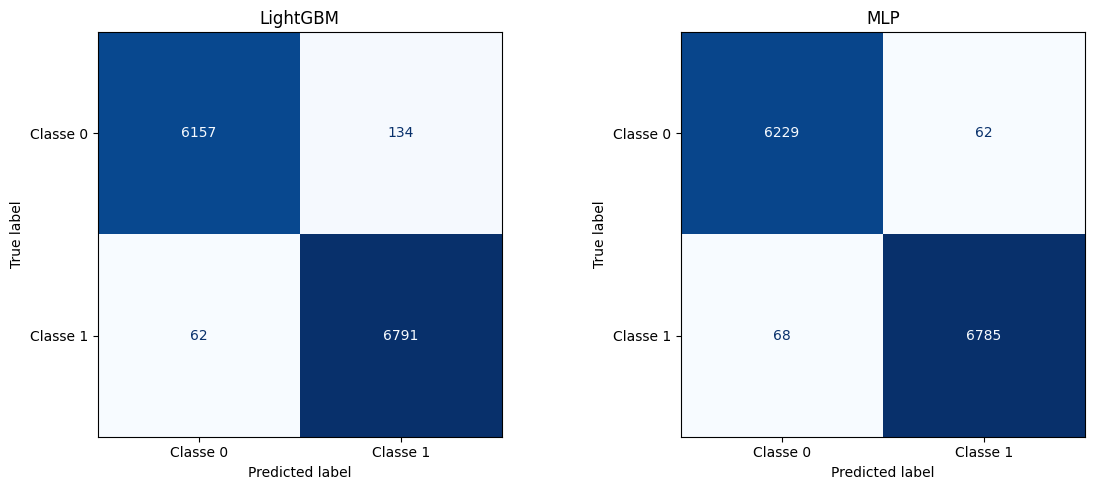

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, nom in zip(axes, ["LightGBM", "MLP"]):
    modele = modeles_ml[nom]

    y_pred = modele.predict(X_val)

    ConfusionMatrixDisplay.from_predictions(
        y_val,
        y_pred,
        labels=[0, 1],
        display_labels=["Classe 0", "Classe 1"],
        cmap="Blues",
        values_format="d",
        ax=ax,
        colorbar=False
    )

    ax.set_title(f"{nom} — Seuil de 0,5")

plt.tight_layout()
plt.show()

In [ ]:
# Analyse des erreurs du MLP

modele = modeles_ml["MLP"]

probas = modele.predict_proba(X_val)[:, 1]
predictions = (probas >= 0.5).astype(int)

analyse_erreurs = pd.DataFrame({
    "texte": X_val.to_numpy(),
    "label_reel": np.asarray(y_val),
    "prediction": predictions,
    "proba_classe_1": probas
})

# Conserver uniquement les erreurs

analyse_erreurs = analyse_erreurs[
    analyse_erreurs["label_reel"] != analyse_erreurs["prediction"]
].copy()

analyse_erreurs["type_erreur"] = np.where(
    analyse_erreurs["label_reel"] == 1,
    "Faux négatif",
    "Faux positif"
)

# Confiance du modèle dans sa prédiction erronée

analyse_erreurs["confiance"] = np.where(
    analyse_erreurs["prediction"] == 1,
    analyse_erreurs["proba_classe_1"],
    1 - analyse_erreurs["proba_classe_1"]
)

analyse_erreurs["apercu"] = analyse_erreurs["texte"].str[:300]

print("Répartition des erreurs :")
display(analyse_erreurs["type_erreur"].value_counts())

print("\nErreurs avec la plus forte confiance :")
display(
    analyse_erreurs.sort_values(
        "confiance", ascending=False
    )[[
        "type_erreur",
        "label_reel",
        "prediction",
        "proba_classe_1",
        "confiance",
        "apercu"
    ]].head(10).round(4)
)

Répartition des erreurs :


,count
type_erreur,
Faux négatif,68
Faux positif,62



Erreurs avec la plus forte confiance :


,type_erreur,label_reel,prediction,proba_classe_1,confiance,apercu
262,Faux négatif,1,0,0.0008,0.9992,cfp int conf web delivering music wedelmusic 2004 barcelona spain sorry multiple reception message want receive information wedelmusic 2004 please...
11968,Faux négatif,1,0,0.0027,0.9973,user7gvcceaschallengecc food network newsletter message contains images dont see images click view august 5 2008 subscribe unsubscribe change emai...
2933,Faux négatif,1,0,0.0041,0.9959,user5gvcceaschallengecc food network newsletter message contains images dont see images click view august 5 2008 subscribe unsubscribe change emai...
9866,Faux négatif,1,0,0.0075,0.9925,invitation review paper ieee trans neural networks giorgo efxaristo pou apodektikes thes kane review mazi dr perantoni kai dose ta stoixoia tou st...
7610,Faux positif,0,1,0.9912,0.9912,pace university evppaceedu messages quarantined potential junk virusinfected messages sent inbox deliver message inbox click deliver link view mes...
4266,Faux négatif,1,0,0.0090,0.9910,utf8bvhjhy2tpbmctvxbkyxrl contactcontactcom daily skimm skimmd stories supportive workplace august 29 2022read browserdaily skimmtogether withskim...
7629,Faux négatif,1,0,0.0114,0.9886,nymex invitation learn power trading power trading fundamentals sept 15 16 nymex nyc early bird discount effect nymex power delegates learn electr...
8528,Faux positif,0,1,0.9872,0.9872,registrationspsscom thank registering account spsscom please use verify email address link complete registration process clicking link activate ac...
11599,Faux positif,0,1,0.9851,0.9851,gift web site http www barrington ltd com
10641,Faux négatif,1,0,0.0164,0.9836,post secondary certificates sale still unioversity deogree lack post graduate education preventing getting better job graduate phd school get dese...


Au seuil de 0,5, LightGBM commet 196 erreurs, contre 130 pour le MLP.

Le MLP réduit fortement les faux positifs (62 contre 134), mais produit légèrement plus de faux négatifs (68 contre 62).

L'inspection des erreurs montre également plusieurs prédictions incorrectes accompagnées d'une confiance supérieure à 99 %. Certains messages classés 1 ressemblent à des newsletters ou à des sollicitations commerciales. Cette observation soulève des interrogations sur la distinction entre spam et phishing dans notre dataset.

Une étude de calibration sera donc nécessaire avant de considérer les probabilités prédites comme suffisamment fiables pour la WebApp.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


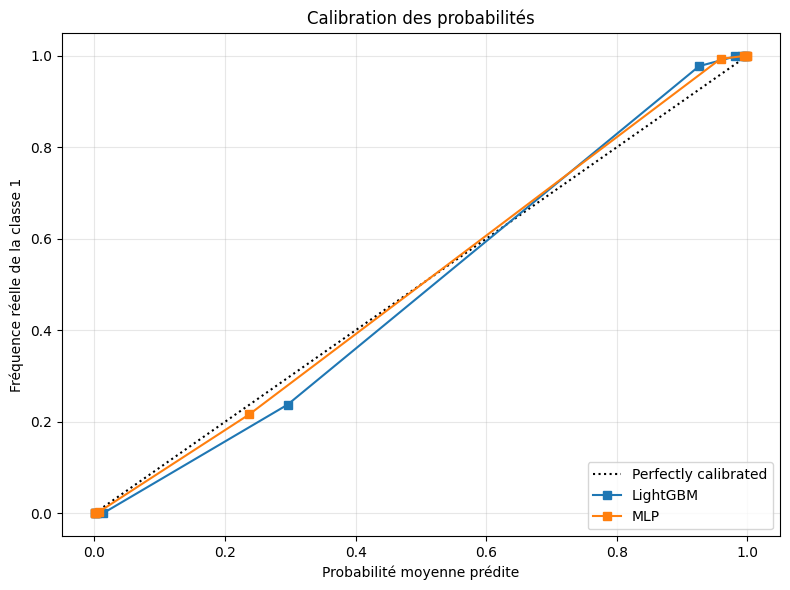

,modèle,Brier,Log Loss,erreurs,erreurs_confiance_90,erreurs_confiance_99
0,LightGBM,0.0124,0.0509,196,20,0
1,MLP,0.0082,0.0350,130,20,6


In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))

resultats_calibration = []

for nom in ["LightGBM", "MLP"]:
    modele = modeles_ml[nom]

    # Probabilités prédites sur la validation
    probas = modele.predict_proba(X_val)[:, 1]
    predictions = (probas >= 0.5).astype(int)

    # Fiabilité des probabilités
    CalibrationDisplay.from_predictions(
        y_val,
        probas,
        n_bins=10,
        strategy="quantile",
        name=nom,
        ax=ax
    )

    # Confiance dans les prédictions incorrectes
    erreurs = predictions != np.asarray(y_val)

    confiance = np.where(
        predictions == 1,
        probas,
        1 - probas
    )

    resultats_calibration.append({
        "modèle": nom,
        "Brier": brier_score_loss(y_val, probas),
        "Log Loss": log_loss(y_val, probas),
        "erreurs": erreurs.sum(),
        "erreurs_confiance_90": (
            erreurs & (confiance >= 0.90)
        ).sum(),
        "erreurs_confiance_99": (
            erreurs & (confiance >= 0.99)
        ).sum()
    })

ax.set_title("Calibration des probabilités")
ax.set_xlabel("Probabilité moyenne prédite")
ax.set_ylabel("Fréquence réelle de la classe 1")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

display(
    pd.DataFrame(resultats_calibration).round(4)
)

Le MLP obtient les meilleurs résultats probabilistes globaux, avec un Brier Score de 0,0082 et une Log Loss de 0,0350, contre respectivement 0,0124 et 0,0509 pour LightGBM.

Les courbes de calibration sont globalement proches de la diagonale, mais le MLP présente six erreurs accompagnées d'une confiance supérieure à 99 %.

Nous analysons donc différents seuils de décision afin d'étudier le compromis entre faux positifs et faux négatifs, particulièrement important dans la détection de messages suspects.

In [ ]:
# Probabilités du MLP sur la validation

modele = modeles_ml["MLP"]
probas_val = modele.predict_proba(X_val)[:, 1]

resultats_seuils = []

for seuil in np.arange(0.1, 1.0, 0.1):
    predictions = (probas_val >= seuil).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    resultats_seuils.append({
        "seuil": round(seuil, 2),
        "precision": precision_score(y_val, predictions),
        "rappel": recall_score(y_val, predictions),
        "f1": f1_score(y_val, predictions),
        "faux_positifs": fp,
        "faux_negatifs": fn
    })

comparaison_seuils = pd.DataFrame(resultats_seuils)

display(comparaison_seuils.round(4))

,seuil,precision,rappel,f1,faux_positifs,faux_negatifs
0,0.1,0.9517,0.9981,0.9744,347,13
1,0.2,0.9720,0.9968,0.9842,197,22
2,0.3,0.9813,0.9952,0.9882,130,33
3,0.4,0.9862,0.9942,0.9902,95,40
4,0.5,0.9909,0.9901,0.9905,62,68
5,0.6,0.9943,0.9856,0.9899,39,99
6,0.7,0.9961,0.9806,0.9883,26,133
7,0.8,0.9982,0.9692,0.9835,12,211
8,0.9,0.9989,0.9428,0.9700,7,392


L'analyse des seuils montre que 0,5 maximise le F1-score parmi les valeurs étudiées (0,9905).

Un seuil de 0,4 permet néanmoins de réduire les faux négatifs de 68 à 40, au prix d'une augmentation des faux positifs de 62 à 95. Le F1-score reste très proche (0,9902).

Nous retenons provisoirement le seuil de 0,4 afin de privilégier le rappel, dans une logique de détection préventive des messages suspects.

Ce seuil est sélectionné sur la validation et devra rester fixe lors de l'évaluation finale. Les performances observées ne garantissent pas la même efficacité sur des messages provenant de nouvelles sources.

In [ ]:
# Seuil retenu sur la validation

SEUIL_MLP = 0.40

modele_mlp = modeles_ml["MLP"]

probas_val_mlp = modele_mlp.predict_proba(X_val)[:, 1]
preds_val_mlp = (probas_val_mlp >= SEUIL_MLP).astype(int)

print(f"Seuil retenu : {SEUIL_MLP}")
print(classification_report(
    y_val,
    preds_val_mlp,
    target_names=["Classe 0", "Classe 1"],
    digits=4
))

print("Matrice de confusion :")
print(confusion_matrix(y_val, preds_val_mlp, labels=[0, 1]))

Seuil retenu : 0.4
              precision    recall  f1-score   support

    Classe 0     0.9936    0.9849    0.9892      6291
    Classe 1     0.9862    0.9942    0.9902      6853

    accuracy                         0.9897     13144
   macro avg     0.9899    0.9895    0.9897     13144
weighted avg     0.9898    0.9897    0.9897     13144

Matrice de confusion :
[[6196   95]
 [  40 6813]]


Les deux modèles obtiennent des performances élevées sur la validation. Le MLP présente les meilleurs résultats globaux, avec un F1-score de 0,9902 au seuil de 0,4 et un Brier Score de 0,0082, contre respectivement 0,9858 et 0,0124 pour LightGBM au seuil de 0,5.

Le seuil de 0,4 permet au MLP de réduire les faux négatifs de 68 à 40 par rapport au seuil de 0,5, au prix d'une augmentation des faux positifs de 62 à 95.

L'analyse de robustesse a révélé une forte dépendance de LightGBM à certaines familles de messages, notamment CNN. Par ailleurs, la présence de textes très similaires entre entraînement et validation invite à relativiser les performances obtenues.

Ces résultats restent donc propres à notre validation et ne garantissent pas une généralisation équivalente à des emails de provenance inconnue.

In [ ]:
# Synthèse des modèles entraînés sur notre partie

resultats_finaux_val = []

for nom, seuil in [("LightGBM", 0.5), ("MLP", 0.4)]:
    modele = modeles_ml[nom]

    probas = modele.predict_proba(X_val)[:, 1]
    preds = (probas >= seuil).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, preds, labels=[0, 1]
    ).ravel()

    resultats_finaux_val.append({
        "modele": nom,
        "seuil": seuil,
        "accuracy": accuracy_score(y_val, preds),
        "precision": precision_score(y_val, preds),
        "recall": recall_score(y_val, preds),
        "f1": f1_score(y_val, preds),
        "faux_positifs": fp,
        "faux_negatifs": fn
    })

comparaison_finalistes = pd.DataFrame(resultats_finaux_val)

display(comparaison_finalistes.round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,modele,seuil,accuracy,precision,recall,f1,faux_positifs,faux_negatifs
0,LightGBM,0.5,0.9851,0.9806,0.9910,0.9858,134,62
1,MLP,0.4,0.9897,0.9862,0.9942,0.9902,95,40


Le MLP obtient les meilleures performances sur la validation, avec une accuracy de 98,97 % et un F1-score de 99,02 %, contre respectivement 98,51 % et 98,58 % pour LightGBM. Avec un seuil de 0,4, le MLP réduit les faux positifs de 134 à 95 et les faux négatifs de 62 à 40 par rapport à LightGBM au seuil de 0,5. Il constitue donc le meilleur candidat parmi les deux modèles étudiés.

Toutefois, les expériences sur les signatures CNN/Enron ont révélé une dépendance de LightGBM à certaines familles de messages. La présence de textes très similaires entre apprentissage et validation limite également les conclusions sur la généralisation.

Le choix définitif nécessitera une comparaison avec les autres modèles du projet et une évaluation finale sur le test réservé.